# 04 · Customer segmentation — who is worth retaining?

**Question:** which customers deserve retention budget, and what should be done
differently for each group?

**Answer:** five segments at the 2011-09-01 snapshot, named from their measured profile.
Champions are 20.5% of buying customers but 72.9% of lifetime revenue. The largest group
is not loyal — it is 1,949 mid-value accounts cooling toward lapse, and it is the only
large reactivation opportunity. The bottom 30.9% are already lapsed one-time buyers.

**Clock:** the latest snapshot with a complete 90-day label window. Every feature is
history-only and every label is future-only, so no customer contributes to both sides.
Churn is measured **only among active customers**, because the definition is undefined for
customers who were already lapsed.

**Definitions:** [`docs/metrics_dictionary.md`](../docs/metrics_dictionary.md). Full
decisions and limitations: [`docs/segmentation.md`](../docs/segmentation.md).

All tables are produced by `uv run python -m hub.analytics.segment_report` and loaded from
`reports/`. The notebook does not refit the model, so its numbers and `reports/segments.json`
cannot drift apart.


In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "reports" / "figures"
evidence = json.loads((ROOT / "reports" / "segments.json").read_text())


def gbp(value: float, digits: int = 0) -> str:
    return f"£{value:,.{digits}f}"

## Population and clock

In [2]:
snapshot = evidence["snapshot"]
chosen = evidence["chosen_model"]
statistical = evidence["statistical_choice"]
thresholds = evidence["features"]["naming_thresholds"]

single_share = snapshot["single_purchase_customers"] / snapshot["customers"]
print(f"Snapshot {snapshot['date'][:10]} | label horizon {snapshot['label_horizon_days']} days")
print(
    f"Buying customers: {snapshot['customers']:,} "
    f"({snapshot['active_customers']:,} active, {snapshot['lapsed_customers']:,} lapsed)"
)
print(f"Refund-only accounts excluded: {snapshot['refund_only_excluded']}")
print(
    f"Single-purchase cadence imputed: {snapshot['single_purchase_customers']:,} "
    f"({single_share:.1%})"
)
print(f"Lifetime gross revenue: {gbp(snapshot['gross_revenue'])}")
print(f"Realised next-90-day revenue: {gbp(snapshot['future_revenue'])}")

Snapshot 2011-09-01 | label horizon 90 days
Buying customers: 5,251 (1,923 active, 3,328 lapsed)
Refund-only accounts excluded: 63
Single-purchase cadence imputed: 1,586 (30.2%)
Lifetime gross revenue: £13,715,058
Realised next-90-day revenue: £2,643,804


The population is every customer who has actually bought at the snapshot. The 63
refund-only accounts (`frequency = 0`) are excluded because they have no purchase invoice,
zero monetary value and zero product diversity: they are a service population, not a value
segment. Segmenting the 1,923 active and 3,328 lapsed customers together is deliberate —
recency is a segmentation axis, and the lapsed base is the win-back pool.

One assumption is visible in the table: 30.2% of customers have only one purchase, so they
have no observed inter-purchase interval. It is imputed with tenure and flagged
per customer. The alternative — dropping the feature — would delete cadence information
for nearly a third of the base.


## Model comparison

silhouette  davies_bouldin  calinski_harabasz  min_cluster_share
algorithm k                                                                  
kmeans    2       0.300           1.260           2344.031              0.409
          3       0.321           1.217           2014.985              0.125
          4       0.335           1.051           1927.254              0.025
          5       0.281           1.085           2038.031              0.024
          6       0.275           1.200           1858.311              0.023
          7       0.235           1.232           1749.892              0.023
          8       0.238           1.195           1666.691              0.022
ward      2       0.274           1.313           2096.717              0.390
          3       0.291           1.128           1703.568              0.056
          4       0.302           0.983           1541.616              0.010
          5       0.203           1.279           1459.896              0.010
          6       0.162           1.485           1417.859              0.010
          7       0.171           1.496           1360.809              0.010
          8       0.176           1.415           1310.212              0.010

Best GMM: k=2, silhouette 0.225


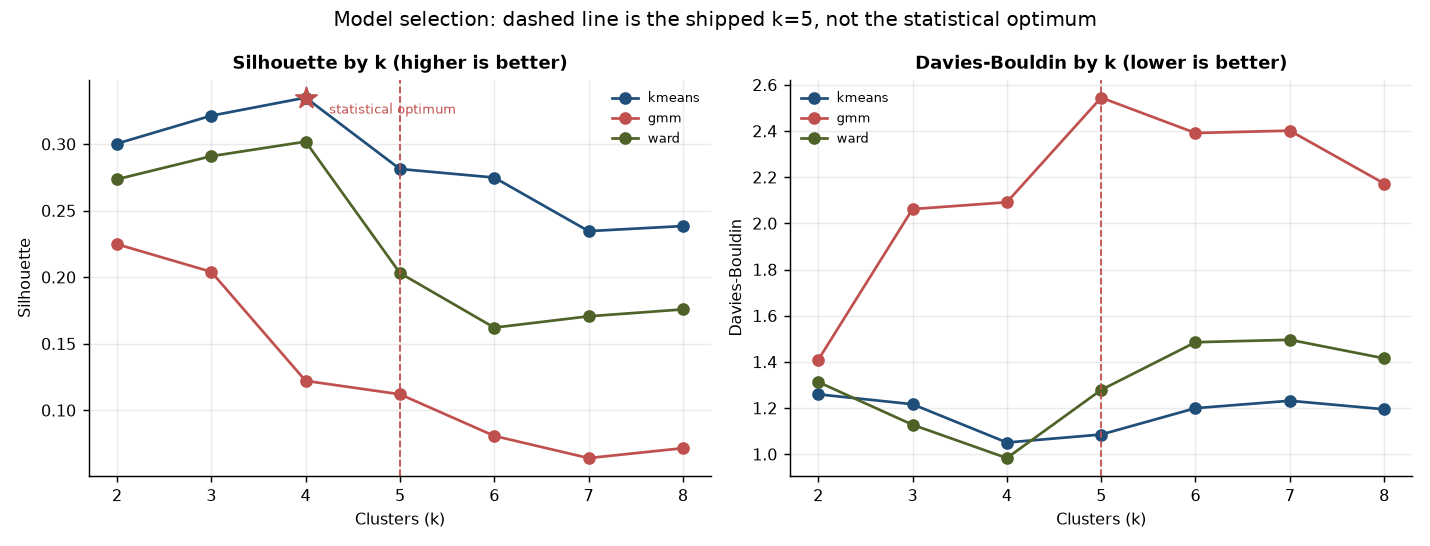

In [3]:
comparison = pd.DataFrame(evidence["model_comparison"])
shown = comparison.loc[
    comparison["algorithm"].isin(["kmeans", "ward"]),
    [
        "algorithm",
        "k",
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz",
        "min_cluster_share",
    ],
]
display(shown.set_index(["algorithm", "k"]).round(3))
best_gmm = (
    comparison.loc[comparison["algorithm"] == "gmm"]
    .sort_values("silhouette", ascending=False)
    .iloc[0]
)
print(f"Best GMM: k={int(best_gmm['k'])}, silhouette {best_gmm['silhouette']:.3f}")
display(Image(filename=str(FIGURES / "segmentation_model_selection.png")))

Three things are visible before any business judgement:

1. **Gaussian mixtures are not competitive.** The best GMM silhouette is 0.225 at k=2 and
   falls to 0.112 by k=5. BIC keeps improving with k because the full covariance structure
   absorbs the continuous features, but the partition is not compact in the scaled space.
   BIC is a density criterion, not a segmentation criterion.
2. **Ward is close but produces unusable clusters.** From k=4 onward about 1% of customers
   (roughly 50 people) are isolated into their own cluster. That fails the 2% size floor:
   it is a micro-group, not a campaign audience.
3. **K-Means is the only family with an actionable solution at every k.** The 2% floor
   leaves k=4 through k=8.


## Why the shipped model is k=5, not the statistical optimum

In [4]:
print(
    f"Statistical optimum: {statistical['algorithm']} k={statistical['k']} "
    f"(silhouette {statistical['silhouette']:.3f}, "
    f"Davies-Bouldin {statistical['davies_bouldin']:.3f})"
)
print(
    f"Shipped: {chosen['algorithm']} k={chosen['k']} "
    f"(silhouette {chosen['silhouette']:.3f}, "
    f"Davies-Bouldin {chosen['davies_bouldin']:.3f})"
)
print()
print(chosen["selection_note"])
print()
composition = pd.DataFrame(evidence["statistical_choice_composition"]).set_index(
    "alternative_cluster"
)
composition.index.name = f"k={statistical['k']} cluster"
display(composition)

Statistical optimum: kmeans k=4 (silhouette 0.335, Davies-Bouldin 1.051)
Shipped: kmeans k=5 (silhouette 0.281, Davies-Bouldin 1.085)

k=4 is the statistical optimum (silhouette 0.335, Davies-Bouldin 1.051), but its 2,571-customer lapsed block holds 1,605 of the 1,623 lapsed one-time buyers alongside 966 of the 1,949 cooling mid-value accounts, and the remaining 857 cooling accounts sit in the high-value cluster: the suppression list and the reactivation opportunity are not separable. k=5 separates them and isolates a returns-heavy account group, costing 0.054 silhouette. k=6 raises Davies-Bouldin by 14% and splits the cooling base at a boundary with no operational meaning, so the search stops at 5.



,Champions,Cooling mid value,Lapsed low value,New / one-time,Returns-heavy accounts,total
k=4 cluster,,,,,,
0,0,966,1605,0,0,2571
1,1078,857,0,0,0,1935
2,1,125,16,474,0,616
3,0,1,2,0,126,129


k=4 wins the statistics. The cross-tab above is computed, not asserted: its 2,571-customer
lapsed block holds **1,605 of the 1,623 lapsed one-time buyers** (98.9%) together with
**966 of the 1,949 cooling mid-value accounts** (49.6%), while the remaining 857 cooling
accounts are folded into the high-value cluster.

| k=4 block | Members | Share of the block | Segment median gross | Churn |
|---|---:|---:|---:|---:|
| Lapsed one-time buyers | 1,605 | 62.4% | £260 | undefined (lapsed) |
| Cooling mid-value accounts | 966 | 37.6% | £1,083 | 44.8% among active |

One group is a suppression list; the other is the only large reactivation opportunity, and
k=4 makes them indistinguishable. k=5 separates them and isolates a returns-heavy account
group, costing 0.054 silhouette. k=6 raises Davies-Bouldin by 14% and splits the cooling
base at a boundary with no operational meaning. This is a documented judgement call, not a
claim that k=5 is statistically optimal — the full curve is shown above.

## Stability: is the partition an artefact of one random start?

100 bootstrap refits | median ARI 0.975 | 10th pct 0.956 | worst 0.928 | refits below 0.5: 0


count    100.000
mean       0.973
std        0.013
min        0.928
25%        0.967
50%        0.975
75%        0.981
max        0.995
Name: adjusted_rand_index, dtype: float64

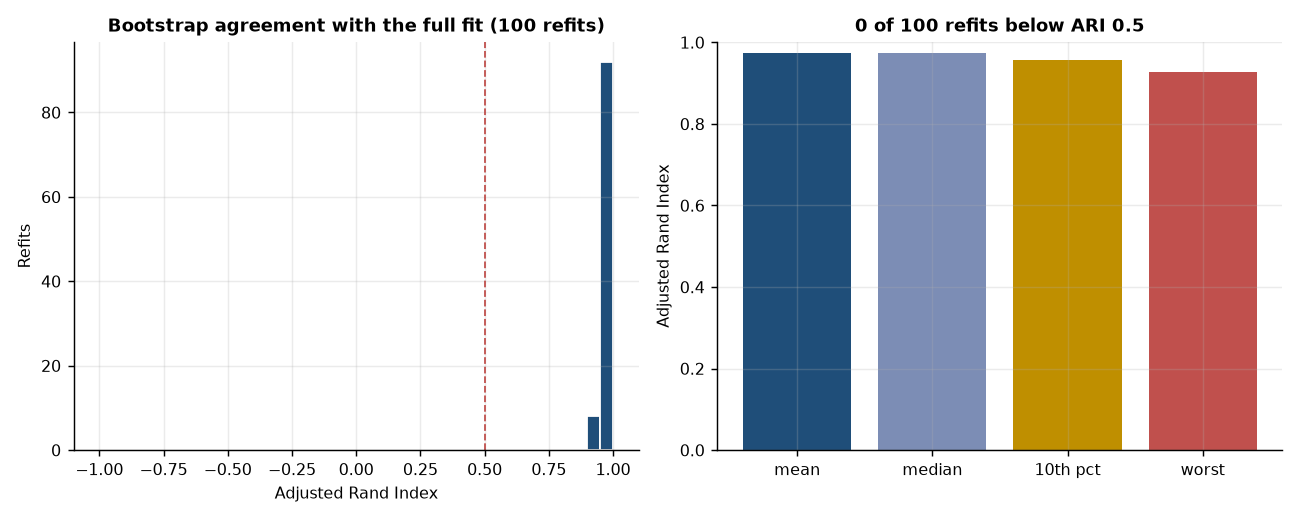

In [5]:
stability = evidence["stability"]
runs = pd.read_csv(TABLES / "segmentation_stability.csv")
print(
    f"{stability['n_bootstrap']} bootstrap refits | "
    f"median ARI {stability['median_ari']:.3f} | "
    f"10th pct {stability['p10_ari']:.3f} | worst {stability['min_ari']:.3f} | "
    f"refits below 0.5: {stability['unstable_runs']}"
)
display(runs["adjusted_rand_index"].describe().round(3))
display(Image(filename=str(FIGURES / "segmentation_stability.png")))

The solution is stable: the worst of 100 bootstrap refits still reproduces 93% of the
pairwise assignment structure (ARI 0.928), and none falls below the 0.5 "unstable" line.
Membership is not an accident of the K-Means seed. This is expected for a partition driven
by two strongly separated axes — recency and value — and it is the reason the segment
names can be used operationally rather than treated as one-off labels.


## Segment profiles

,customers,share_of_base,lifetime_rev_share,next90_rev_share,active_share,churn_active,median_recency,median_invoices,median_gross,median_products
segment,,,,,,,,,,
Champions,1079,0.205,0.729,0.706,0.871,0.163,24.0,12.0,4500.930,149.0
Cooling mid value,1949,0.371,0.196,0.173,0.263,0.448,181.0,4.0,1083.000,56.0
Lapsed low value,1623,0.309,0.039,0.041,0.033,0.679,325.0,1.0,259.680,16.0
New / one-time,474,0.090,0.019,0.074,0.846,0.456,38.0,1.0,385.985,23.0
Returns-heavy accounts,126,0.024,0.017,0.006,0.127,0.688,269.5,2.0,410.930,7.5


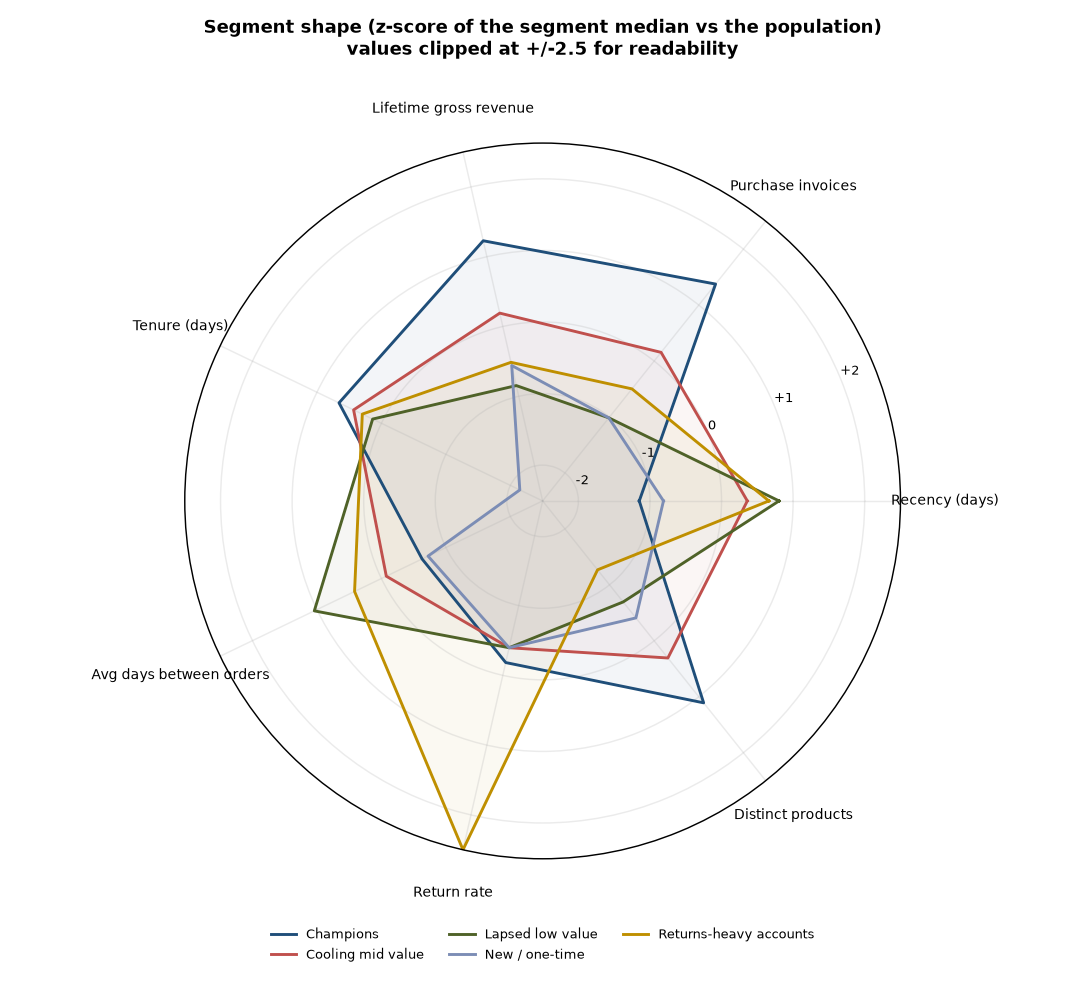

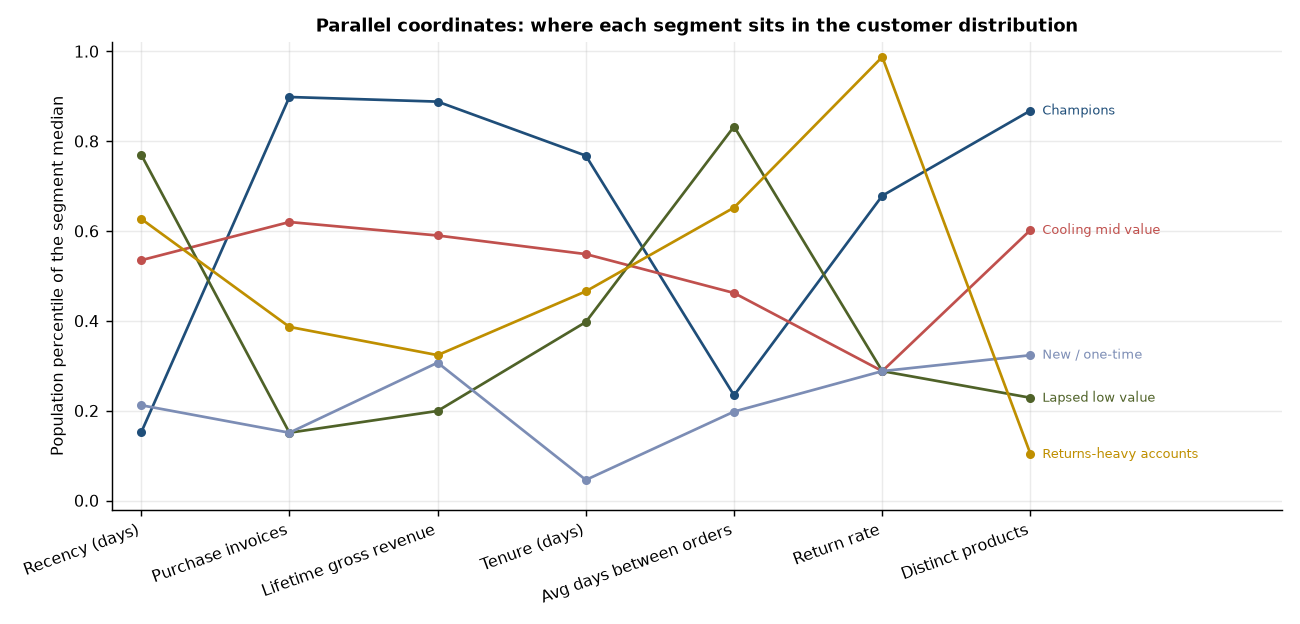

In [6]:
profiles = pd.DataFrame(evidence["segments"]).set_index("segment")
view = pd.DataFrame(
    {
        "customers": profiles["customers"],
        "share_of_base": profiles["share_of_customers"],
        "lifetime_rev_share": profiles["gross_revenue_share"],
        "next90_rev_share": profiles["future_revenue_share"],
        "active_share": profiles["active_share"],
        "churn_active": profiles["churn_rate_among_active"],
        "median_recency": profiles["median_recency_days"],
        "median_invoices": profiles["median_frequency"],
        "median_gross": profiles["median_gross_revenue"],
        "median_products": profiles["median_distinct_products"],
    }
)
display(view.round(3))
display(Image(filename=str(FIGURES / "segment_radar.png")))
display(Image(filename=str(FIGURES / "segment_parallel_coordinates.png")))

Churn is computed only among active customers. Lapsed low value has 53 active customers
and Returns-heavy accounts has 16, so their churn rates are shown for completeness but
should not be read as precise. Forward revenue is the **realised** revenue in the 90 days
after the snapshot, not a forecast; it is used as a value check.

The two profile charts answer different questions. The radar shows the shape of each
segment in standard deviations from the population; returns-heavy accounts blow past the
plot at a return-rate z-score above 6 (clipped at 2.5). The parallel coordinates show the
same medians as population percentiles, which is easier to read for skewed features.


In [7]:
percentiles = pd.read_csv(TABLES / "segment_percentiles.csv", index_col=0)
display(percentiles.round(2))
print({key: round(value, 2) for key, value in thresholds.items()})

,recency_days,frequency,gross_revenue,tenure_days,avg_days_between_orders,return_rate,distinct_products
segment,,,,,,,
Champions,0.15,0.90,0.89,0.77,0.23,0.68,0.87
Cooling mid value,0.54,0.62,0.59,0.55,0.46,0.29,0.60
Lapsed low value,0.77,0.15,0.20,0.40,0.83,0.29,0.23
New / one-time,0.21,0.15,0.31,0.05,0.20,0.29,0.32
Returns-heavy accounts,0.63,0.39,0.32,0.47,0.65,0.99,0.10


{'recency_p25': 48.0, 'recency_p75': 316.5, 'frequency_p75': 6.0, 'gross_p25': 317.1, 'gross_p75': 2058.2, 'tenure_p25': 307.0}


### How the names were earned

Names are generated by a deterministic rule set, not copied from the brief. Every name
traces back to a median crossing a population quartile:

- **Champions** — 87.1% active, median recency 24 days (≤ p25 of 48), 12 invoices (≥ p75 of
  6), £4,501 lifetime gross (≥ p75 of £2,058), 149 products. The wholesale/regular core.
- **Cooling mid value** — only 26.3% active, median recency 181 days, gross between the
  quartiles. The name describes state, not intent: most are inactive, a quarter still buy.
- **Lapsed low value** — 3.3% active, 325-day recency, one invoice, £260 gross (≤ p25),
  16 products. The long tail of one-and-done buyers.
- **New / one-time** — 84.6% active, median tenure 73 days (≤ p25 of 307), one invoice,
  £386. Recent first purchase, no repeat yet.
- **Returns-heavy accounts** — median return rate 33.3% against a population median of 0,
  8 products, 12.7% active. A remediation group, not a value tier.

No segment is called "At-Risk Champions" or "Lost Customers" without the medians to support
it; the rule set is unit-tested, and duplicate archetypes are disambiguated by value.


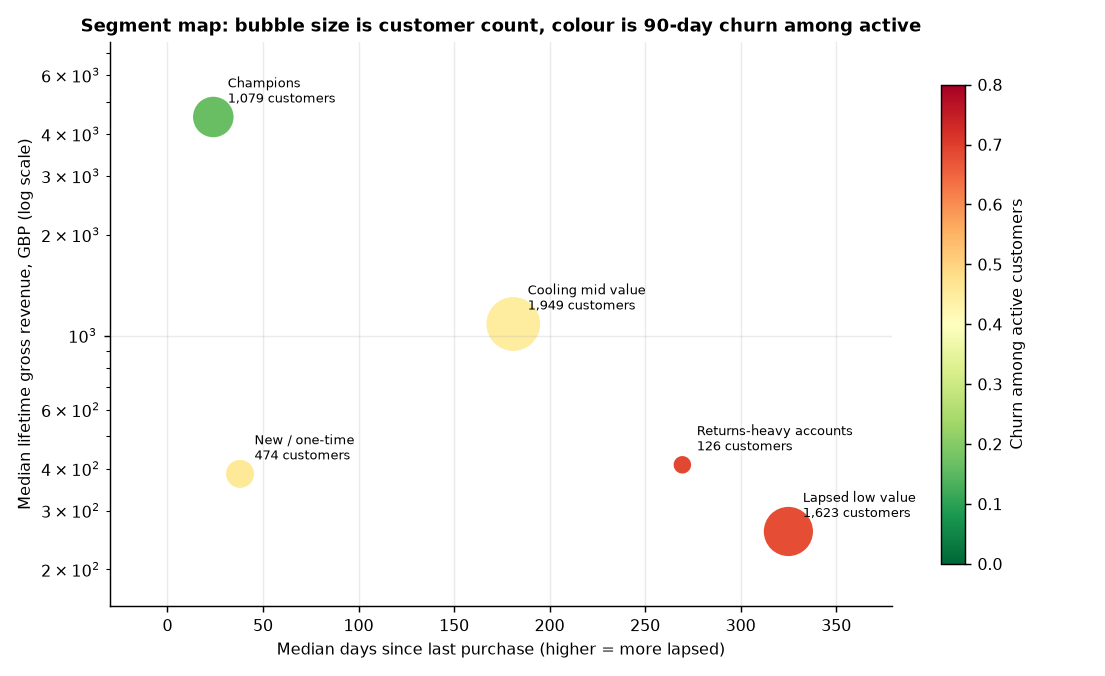

In [8]:
display(Image(filename=str(FIGURES / "segment_map.png")))

The map makes the concentration concrete: Champions sit in the low-recency, high-value
corner and are the only large green (low-churn) bubble. The three lapsed groups sit on the
right, and the cooling group sits in the middle — still close enough to act on.


## The rule-based RFM baseline

,customers,share_of_base,churn_active,lifetime_rev_share,next90_rev_share,next90_per_customer
segment,,,,,,
Champions,1208,0.230,0.190,0.706,0.722,1580.957
Loyal,937,0.178,0.477,0.139,0.110,310.285
At risk — high value,199,0.038,NaN,0.047,0.019,256.738
Hibernating,1339,0.255,NaN,0.041,0.037,72.560
At risk,562,0.107,NaN,0.035,0.027,126.899
New / promising,367,0.070,0.515,0.014,0.056,404.190
Occasional,395,0.075,NaN,0.012,0.017,113.695
Core,244,0.046,0.525,0.007,0.012,124.831


ARI between the ML and rule partitions: 0.373


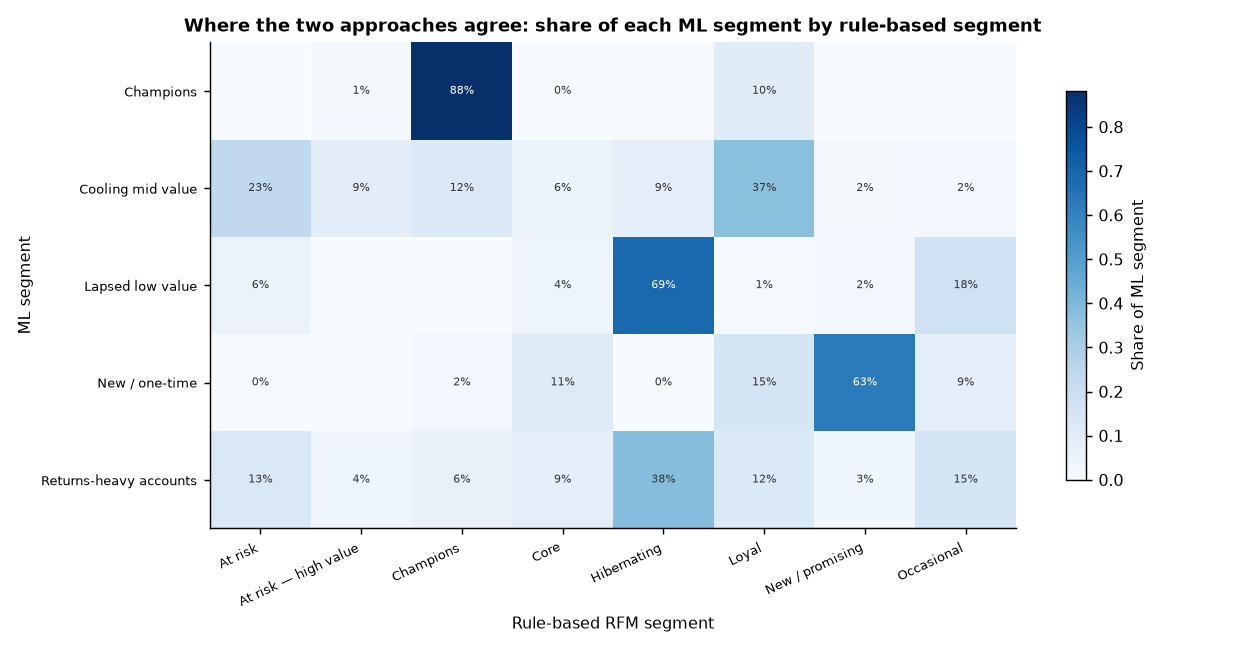

In [9]:
rfm = pd.DataFrame(evidence["rfm_baseline"]["profiles"]).set_index("segment")
rfm_view = pd.DataFrame(
    {
        "customers": rfm["customers"],
        "share_of_base": rfm["share_of_customers"],
        "churn_active": rfm["churn_rate_among_active"],
        "lifetime_rev_share": rfm["gross_revenue_share"],
        "next90_rev_share": rfm["future_revenue_share"],
        "next90_per_customer": rfm["future_revenue_per_customer"],
    }
)
display(rfm_view.round(3))
print(f"ARI between the ML and rule partitions: {evidence['rfm_baseline']['agreement_ari']:.3f}")
display(Image(filename=str(FIGURES / "rfm_vs_clusters.png")))

Classic quintile RFM produces eight segments. It agrees with the clustering at **ARI
0.374** — related, but not interchangeable. 88% of ML Champions are also rule-based
Champions; 69% of Lapsed low value are rule-based Hibernating; 63% of New / one-time are
rule-based New / promising.

The differences are the point:

- Four rule segments contain **no active customers** ("At risk", "At risk — high value",
  "Hibernating" and "Occasional"; 2,495 customers, 47.5% of the base). Their churn rate is
  undefined, not zero, because low recency means already lapsed under this churn
  definition. The ML partition keeps the cooling base as one actionable group and
  separates lapsed from active by construction.
- ML churn spans 16.3% to 68.8% across segments (52.5 points), against 19.0% to 52.5%
  (33.4 points) for the rule segments that contain active customers. The ML partition
  separates outcome risk more sharply, which is what a retention budget needs.
- The rules give more labels but less actionability: several are value tiers rather than
  treatments, and the largest rule segment ("Hibernating", 25.5% of customers) earns only
  4.1% of lifetime revenue.

The honest conclusion is that the rules are a good sanity check and a cheap first pass,
but they are not a substitute for clustering when the decision depends on separating a
large cooling base from an already-lapsed tail.

## Strategy matrix

,customers,action,channel,assumed_uplift,incremental_revenue_estimate,campaign_cost_estimate,net_estimate
segment,,,,,,,
Champions,1079,"Protect the account: named contact, early acce...",Account management,0.10,186749.77,26975.00,159774.77
Cooling mid value,1949,Reactivate before lapse: personalised reminder...,Email,0.04,18262.80,1949.00,16313.80
New / one-time,474,Convert: second-purchase incentive inside 30 d...,Email + voucher,0.05,9771.21,1422.00,8349.21
Lapsed low value,1623,"Suppress from paid channels; email only, no in...",Email,0.00,546.51,81.15,465.36
Returns-heavy accounts,126,Remediate first: audit refund reasons and fix ...,Service recovery,0.00,0.00,630.00,-630.00


,uplift_basis
segment,
Champions,Assumed 10% lift on realised 90-day revenue
Cooling mid value,Assumed 4% lift on realised 90-day revenue
New / one-time,Assumed 5% conversion of one-time buyers into ...
Lapsed low value,"Assumed 0.5% reactivation, valued at realised ..."
Returns-heavy accounts,No campaign uplift is assumed until the return...


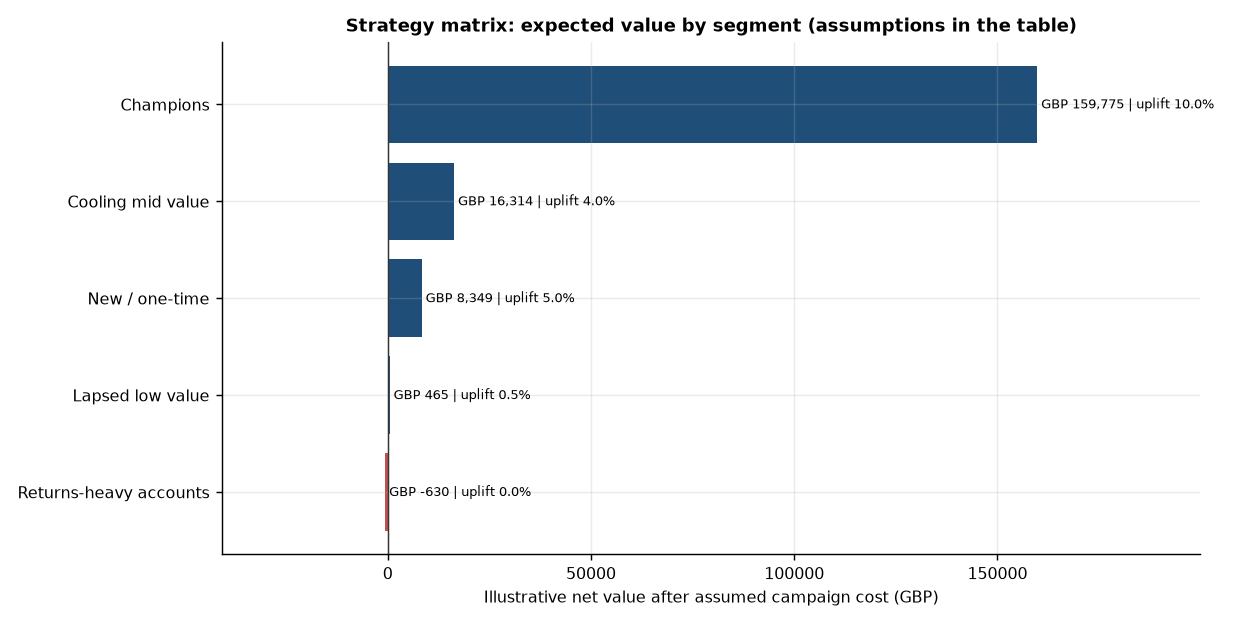

In [10]:
strategy = pd.DataFrame(evidence["strategy"]).set_index("segment")
strategy_view = strategy[
    [
        "customers",
        "action",
        "channel",
        "assumed_uplift",
        "incremental_revenue_estimate",
        "campaign_cost_estimate",
        "net_estimate",
    ]
]
display(strategy_view.round(2))
display(strategy[["uplift_basis"]])
display(Image(filename=str(FIGURES / "segment_strategy.png")))

These are illustrative expected values, not causal estimates. Each uplift is an explicit
assumption applied to the segment's realised next-90-day revenue; costs are assumed per
customer. The table exists to rank where effort is worth testing, not to promise a return.
Phase 7 replaces these assumptions with expected-value targeting and an A/B test design.

The ordering is not a surprise, but the magnitudes are. Champions are worth roughly 10×
the next segment and 340× the lapsed tail. A campaign that spreads budget evenly across
5,251 customers is mostly a transfer to customers who were going to buy anyway. The
returns-heavy group has negative expected net value as a campaign and should be an
operational investigation, not a marketing audience.


## So what?

1. **Protect the 20% that funds the business.** 1,079 Champions generate 72.9% of lifetime
   revenue and 70.6% of the next 90 days, with the lowest churn (16.3%). Service quality —
   not discounting — is the lever.
2. **The biggest addressable leak is the cooling mid-value base.** 1,949 customers, 19.6%
   of lifetime revenue, 26.3% still active, 44.8% churn among those active. It is the only
   large group where a reactivation sequence has both reach and value.
3. **Stop paying to reach the lapsed one-time tail.** 1,623 customers, 3.9% of lifetime
   revenue, 3.3% active, £67 forward revenue per customer. At any realistic contact cost,
   paid reacquisition is negative margin; email suppression is the correct action.
4. **New buyers are a conversion problem, not a retention problem.** 474 customers with a
   median tenure of 73 days, 84.6% still active, 45.6% churn. The second purchase is the
   decision point and it happens inside the first quarter.
5. **Treat returns as an operational signal.** 126 accounts have a median return rate of
   33.3% and only 8 distinct products. Their forward value is consumed by refunds. The
   first step is a refund-reason audit, before any offer.

## Limitations

- One snapshot (2011-09-01). Membership will drift; segment-level drift over time is not
  measured here.
- K-Means assumes roughly spherical, equal-variance clusters in the scaled space. The
  result is stable and interpretable, but adjacent value-tier boundaries are not causal.
- Churn is a 90-day label. A customer who would have returned in month four is counted as
  churned. Segment rankings are robust to the window; the absolute level is not.
- Cadence is imputed for 30.2% of the base. Single-purchase customers are assigned tenure
  as an interval; this is defensible but is still an assumption.
- `M` is lifetime gross revenue, so refunds are not netted out of value; they are carried
  by `return_rate`. A high-gross, high-refund account can still look valuable on M.
- The strategy uplifts are assumptions. No causal claim is made and no experiment has been
  run; Phase 7 is where that changes.
